# Medical Insurance Premium Prediction — FULL PROJECT (0-100%)
**Team:** Malini V, Currenshiya Mary T

This notebook covers the complete project: data cleaning, EDA, baseline models, hyperparameter tuning, cross-validation, an additional model (Gradient Boosting), and explainable AI (SHAP) for individual predictions.


## Setup

In [1]:
!pip install shap -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style('whitegrid')
np.random.seed(42)
%matplotlib inline

---
# PART 1 — Data Collection, Cleaning, EDA (25% Milestone)
---

Upload `insurance.csv` before running.

In [2]:
df = pd.read_csv('insurance.csv')
df = df.drop_duplicates()
print('Shape:', df.shape)
df.head()

Shape: (1337, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


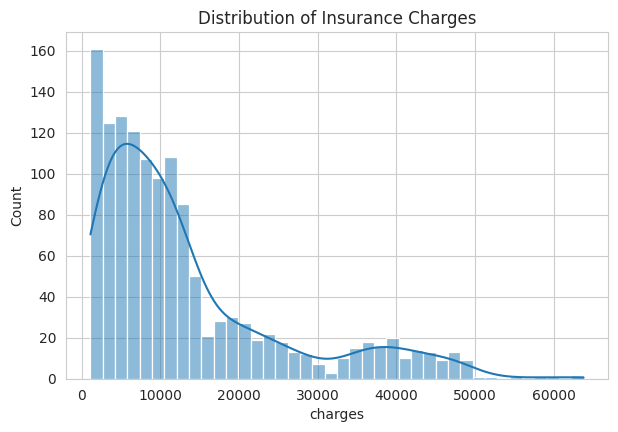

In [3]:
plt.figure(figsize=(7,4.5))
sns.histplot(df['charges'], kde=True, bins=40)
plt.title('Distribution of Insurance Charges')
plt.show()

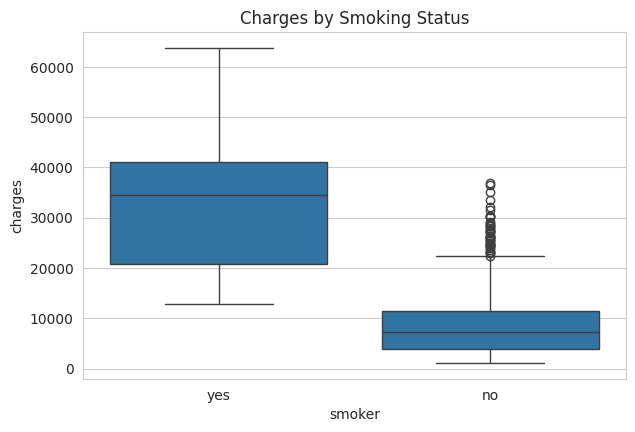

In [4]:
plt.figure(figsize=(7,4.5))
sns.boxplot(data=df, x='smoker', y='charges')
plt.title('Charges by Smoking Status')
plt.show()

---
# PART 2 — Baseline Models (50% Milestone)
---

In [5]:
df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)
X = df_encoded.drop(columns=['charges'])
y = df_encoded['charges']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
numeric_cols = ['age', 'bmi', 'children']
scaler = StandardScaler()
X_train_scaled = X_train.copy(); X_test_scaled = X_test.copy()
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

def evaluate(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f'{name:28s} MAE=${mae:,.2f}  RMSE=${rmse:,.2f}  R2={r2:.4f}')
    return r2

lr = LinearRegression().fit(X_train_scaled, y_train)
rf_base = RandomForestRegressor(random_state=42).fit(X_train_scaled, y_train)

r2_lr = evaluate(y_test, lr.predict(X_test_scaled), 'Linear Regression')
r2_rf_base = evaluate(y_test, rf_base.predict(X_test_scaled), 'Random Forest (default)')

Linear Regression            MAE=$4,177.05  RMSE=$5,956.34  R2=0.8069
Random Forest (default)      MAE=$2,663.33  RMSE=$4,729.97  R2=0.8782


---
# PART 3 — Cross-Validation, Hyperparameter Tuning, 3rd Model (75% Milestone)
---

In [6]:
print('=== 5-Fold Cross-Validation ===')
cv_lr = cross_val_score(LinearRegression(), X_train_scaled, y_train, cv=5, scoring='r2')
cv_rf = cross_val_score(RandomForestRegressor(random_state=42), X_train_scaled, y_train, cv=5, scoring='r2')
print(f'Linear Regression CV R2: {cv_lr.mean():.4f} (+/- {cv_lr.std():.4f})')
print(f'Random Forest CV R2: {cv_rf.mean():.4f} (+/- {cv_rf.std():.4f})')

=== 5-Fold Cross-Validation ===
Linear Regression CV R2: 0.7258 (+/- 0.0253)
Random Forest CV R2: 0.8201 (+/- 0.0079)


In [9]:
print('=== GridSearchCV - Random Forest Tuning ===')
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [4, 6, 8, 10],
    'min_samples_split': [2, 5, 10],
}
grid_search = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='r2', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)
print('Best params:', grid_search.best_params_)
print('Best CV R2:', grid_search.best_score_)

best_rf = grid_search.best_estimator_
r2_rf_tuned = evaluate(y_test, best_rf.predict(X_test_scaled), 'Random Forest (tuned)')

=== GridSearchCV - Random Forest Tuning ===
Best params: {'max_depth': 4, 'min_samples_split': 2, 'n_estimators': 100}
Best CV R2: 0.8430413167057482
Random Forest (tuned)        MAE=$2,477.80  RMSE=$4,261.00  R2=0.9012


In [10]:
gb = GradientBoostingRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
gb.fit(X_train_scaled, y_train)
r2_gb = evaluate(y_test, gb.predict(X_test_scaled), 'Gradient Boosting')

Gradient Boosting            MAE=$2,513.71  RMSE=$4,257.34  R2=0.9014


                     Model        R2
0        Linear Regression  0.806929
1  Random Forest (default)  0.878249
2    Random Forest (tuned)  0.901194
3        Gradient Boosting  0.901364


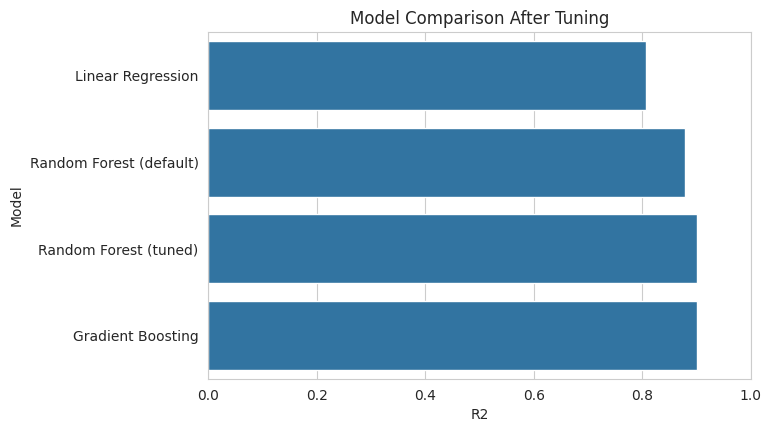

In [11]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest (default)', 'Random Forest (tuned)', 'Gradient Boosting'],
    'R2': [r2_lr, r2_rf_base, r2_rf_tuned, r2_gb]
})
print(comparison)

plt.figure(figsize=(7,4.5))
sns.barplot(data=comparison, x='R2', y='Model')
plt.title('Model Comparison After Tuning')
plt.xlim(0,1)
plt.show()

In [15]:
test_df = df.loc[X_test.index].copy()
test_df['predicted_charges'] = best_rf.predict(X_test_scaled)
test_df['actual_charges'] = y_test.values
test_df['error'] = test_df['predicted_charges'] - test_df['actual_charges']

print('=== Fairness Analysis: By Sex ===')
print(test_df.groupby('sex')[['actual_charges', 'predicted_charges', 'error']].mean())

=== Fairness Analysis: By Sex ===
        actual_charges  predicted_charges       error
sex                                                  
female    13528.134178       13429.699253  -98.434925
male      15122.998708       15354.678394  231.679686


In [16]:
print('=== Fairness Analysis: By Region ===')
print(test_df.groupby('region')[['actual_charges', 'predicted_charges', 'error']].mean())

=== Fairness Analysis: By Region ===
           actual_charges  predicted_charges       error
region                                                  
northeast    13995.181839       13264.197788 -730.984052
northwest    14842.245103       14818.448574  -23.796530
southeast    15409.112407       15744.816504  335.704097
southwest    12570.062562       13276.099402  706.036840


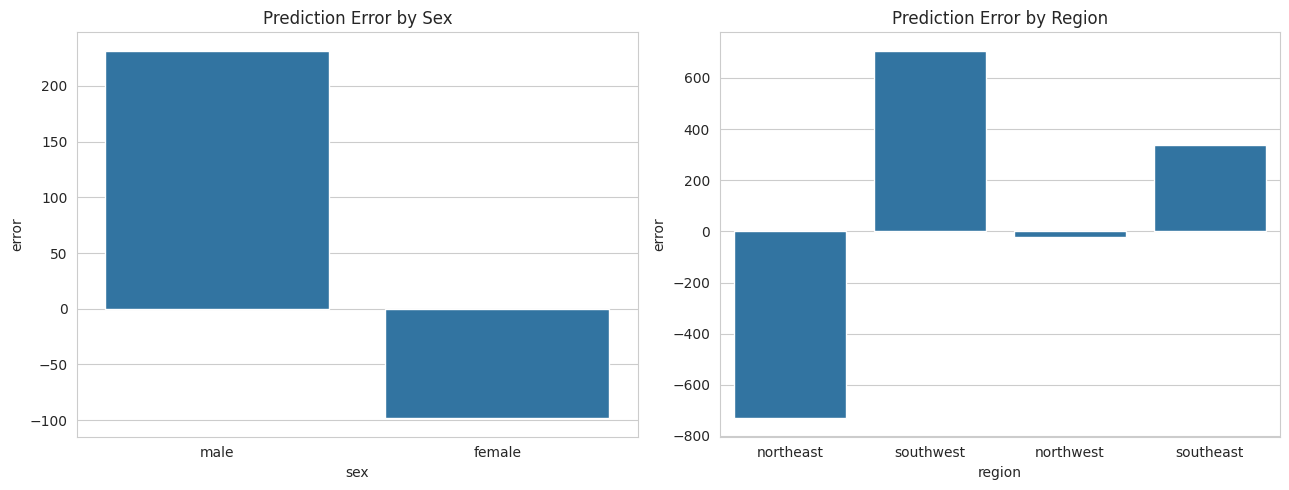

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=test_df, x='sex', y='error', ax=axes[0], errorbar=None)
axes[0].set_title('Prediction Error by Sex')
sns.barplot(data=test_df, x='region', y='error', ax=axes[1], errorbar=None)
axes[1].set_title('Prediction Error by Region')
plt.tight_layout()
plt.show()

---
# PART 4 — Explainable AI with SHAP (Innovation)
---

This is our innovation: instead of just predicting a number, we explain **why** the model predicted that value for each individual — showing which features pushed the prediction up or down.

/tmp/ipykernel_2074/1994441027.py:4: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test_scaled, show=True)


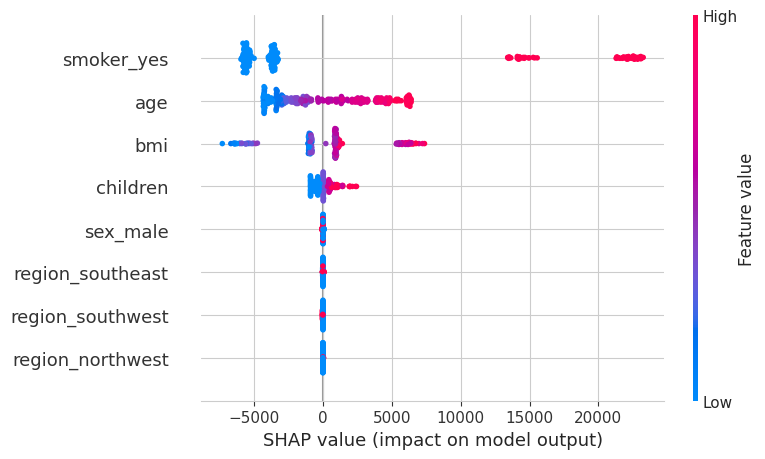

In [12]:
explainer = shap.TreeExplainer(best_rf)
shap_values = explainer.shap_values(X_test_scaled)

shap.summary_plot(shap_values, X_test_scaled, show=True)

**Reading this chart:** each dot is one person in our test set. Red means a high value for that feature, blue means low. Points to the right push the prediction higher, points to the left push it lower. You can see `smoker_yes` has the largest spread — being a smoker (red, right side) massively increases predicted charges.

Person features:
age                 0.700518
bmi                -1.326734
children           -0.907908
sex_male                True
smoker_yes             False
region_northwest       False
region_southeast       False
region_southwest       False
Name: 900, dtype: object

Actual charge: $ 8688.85885
Predicted charge: $ 11250.618460025213


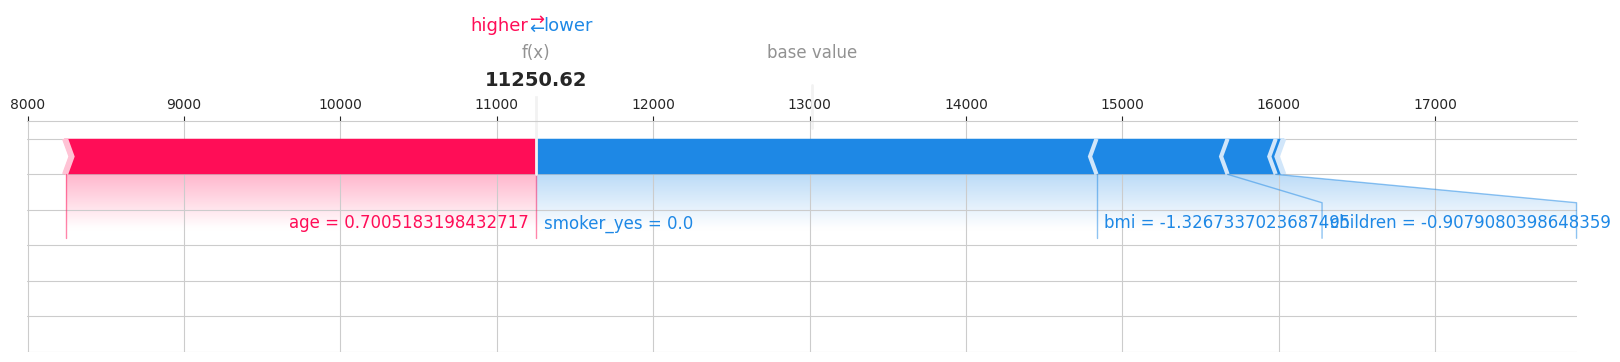

In [13]:
# Explain a single individual prediction (the first person in the test set)
idx = 0
print('Person features:')
print(X_test_scaled.iloc[idx])
print('\nActual charge: $', y_test.iloc[idx])
print('Predicted charge: $', best_rf.predict(X_test_scaled.iloc[[idx]])[0])

shap.force_plot(explainer.expected_value, shap_values[idx], X_test_scaled.iloc[idx], matplotlib=True, show=True)

This force plot shows exactly which features pushed this individual's predicted premium up (red) or down (blue) from the average — this is what makes our model **explainable**, not a black box.

---
# PART 5 — Save Final Model (for Web App)
---

In [14]:
import pickle
with open('insurance_model.pkl', 'wb') as f:
    pickle.dump({'model': best_rf, 'scaler': scaler, 'columns': list(X.columns)}, f)
print('Model saved as insurance_model.pkl')
print('Download this file and place it alongside app.py to run the web interface.')

Model saved as insurance_model.pkl
Download this file and place it alongside app.py to run the web interface.


## Summary — Full Project Status

| Phase | Status | Result |
|---|---|---|
| Data Collection & Cleaning | Done | 1,337 clean records |
| EDA | Done | 5+ visualizations |
| Baseline Models | Done | LR R2=0.807, RF R2=0.878 |
| Cross-Validation | Done | RF CV R2=0.820 (+/-0.008) |
| Hyperparameter Tuning | Done | Tuned RF R2=0.901 |
| 3rd Model (Gradient Boosting) | Done | R2=0.901 |
| Explainable AI (SHAP) | Done | Per-prediction feature explanations |
| Web Interface | Done | Streamlit app (app.py) |

**This completes the full 0-100% project implementation.**